In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [3]:
data = pd.read_csv("../data/raw/DataCoSupplyChainDataset.csv", encoding="latin-1")
df = pd.DataFrame(data)

In [4]:
df.shape

(180519, 53)

# **EDA**

# **Data Quality**

In [5]:
#  SCHEMA OVERVIEW
dtype_count=df.dtypes.value_counts()
dataset_info=pd.DataFrame({
    "columns":df.columns,
    "Data Type":df.dtypes.values,
    "Non Null Values":df.notnull().sum().values,
    "Null Values":df.isnull().sum().values,
    "Null_Percentage" : (df.isnull().sum()/len(df)*100).round(2).values,
    "Unique Values":df.nunique().values,
    "Sample Values":[df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns]
})


for dtypes,count in dtype_count.items():
  print(f"{dtypes}:{count}")

dataset_info

str:24
float64:15
int64:14


,columns,Data Type,Non Null Values,Null Values,Null_Percentage,Unique Values,Sample Values
0,Type,str,180519,0,0.00,4,DEBIT
1,Days for shipping (real),int64,180519,0,0.00,7,3
2,Days for shipment (scheduled),int64,180519,0,0.00,4,4
3,Benefit per order,float64,180519,0,0.00,21998,91.25
4,Sales per customer,float64,180519,0,0.00,2927,314.640015
5,Delivery Status,str,180519,0,0.00,4,Advance shipping
6,Late_delivery_risk,int64,180519,0,0.00,2,0
7,Category Id,int64,180519,0,0.00,51,73
8,Category Name,str,180519,0,0.00,50,Sporting Goods
9,Customer City,str,180519,0,0.00,563,Caguas


In [6]:
# Missing values
total_missing_values = df.isnull().sum().sum()
missing_columns = (df.isnull().sum()>0).sum()
high_missing_cols= dataset_info[dataset_info["Null_Percentage"]>50]["columns"].tolist()
# Duplicate rows
duplicate_rows = df.duplicated().sum()

print(f"Total missing values: {total_missing_values}")
print(f"Number of columns with missing values: {missing_columns}")
print(f"Columns with more than 50% missing values: {high_missing_cols}")
print(f"Duplicate rows: {duplicate_rows}")

Total missing values: 336209
Number of columns with missing values: 4
Columns with more than 50% missing values: ['Order Zipcode', 'Product Description']
Duplicate rows: 0


In [46]:
duplicate_column_pairs = []

for x in range(df.shape[1]):
    for y in range(x + 1, df.shape[1]):

        if df.iloc[:, x].equals(df.iloc[:, y]):
            duplicate_column_pairs.append(
                (df.columns[x], df.columns[y])
            )

print("Duplicate column pairs:")
for col1, col2 in duplicate_column_pairs:
    print(f"{col1}  <-->  {col2}")

Duplicate column pairs:
Benefit per order  <-->  Order Profit Per Order
Sales per customer  <-->  Order Item Total
Category Id  <-->  Product Category Id
Customer Email  <-->  Customer Password
Customer Id  <-->  Order Customer Id
Order Item Cardprod Id  <-->  Product Card Id
Order Item Product Price  <-->  Product Price


# UNIVARITE ANALYSIS


**Univariate — Numeric**

In [47]:
numerical_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Benefit per order",
    "Sales per customer",
    "Sales",
    "Order Item Product Price",
    "Order Item Quantity",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Profit Ratio",
]
df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.00000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.00000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.97998,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.49000,104.379997,163.990005,247.399994,1939.989990
Sales,180519.0,203.772096,132.273077,9.99000,119.980003,199.919998,299.950012,1999.989990
Order Item Product Price,180519.0,141.232550,139.732492,9.99000,50.000000,59.990002,199.990005,1999.989990
Order Item Quantity,180519.0,2.127638,1.453451,1.00000,1.000000,1.000000,3.000000,5.000000
Order Item Discount,180519.0,20.664741,21.800901,0.00000,5.400000,14.000000,29.990000,500.000000
Order Item Discount Rate,180519.0,0.101668,0.070415,0.00000,0.040000,0.100000,0.160000,0.250000
Order Item Profit Ratio,180519.0,0.120647,0.466796,-2.75000,0.080000,0.270000,0.360000,0.500000


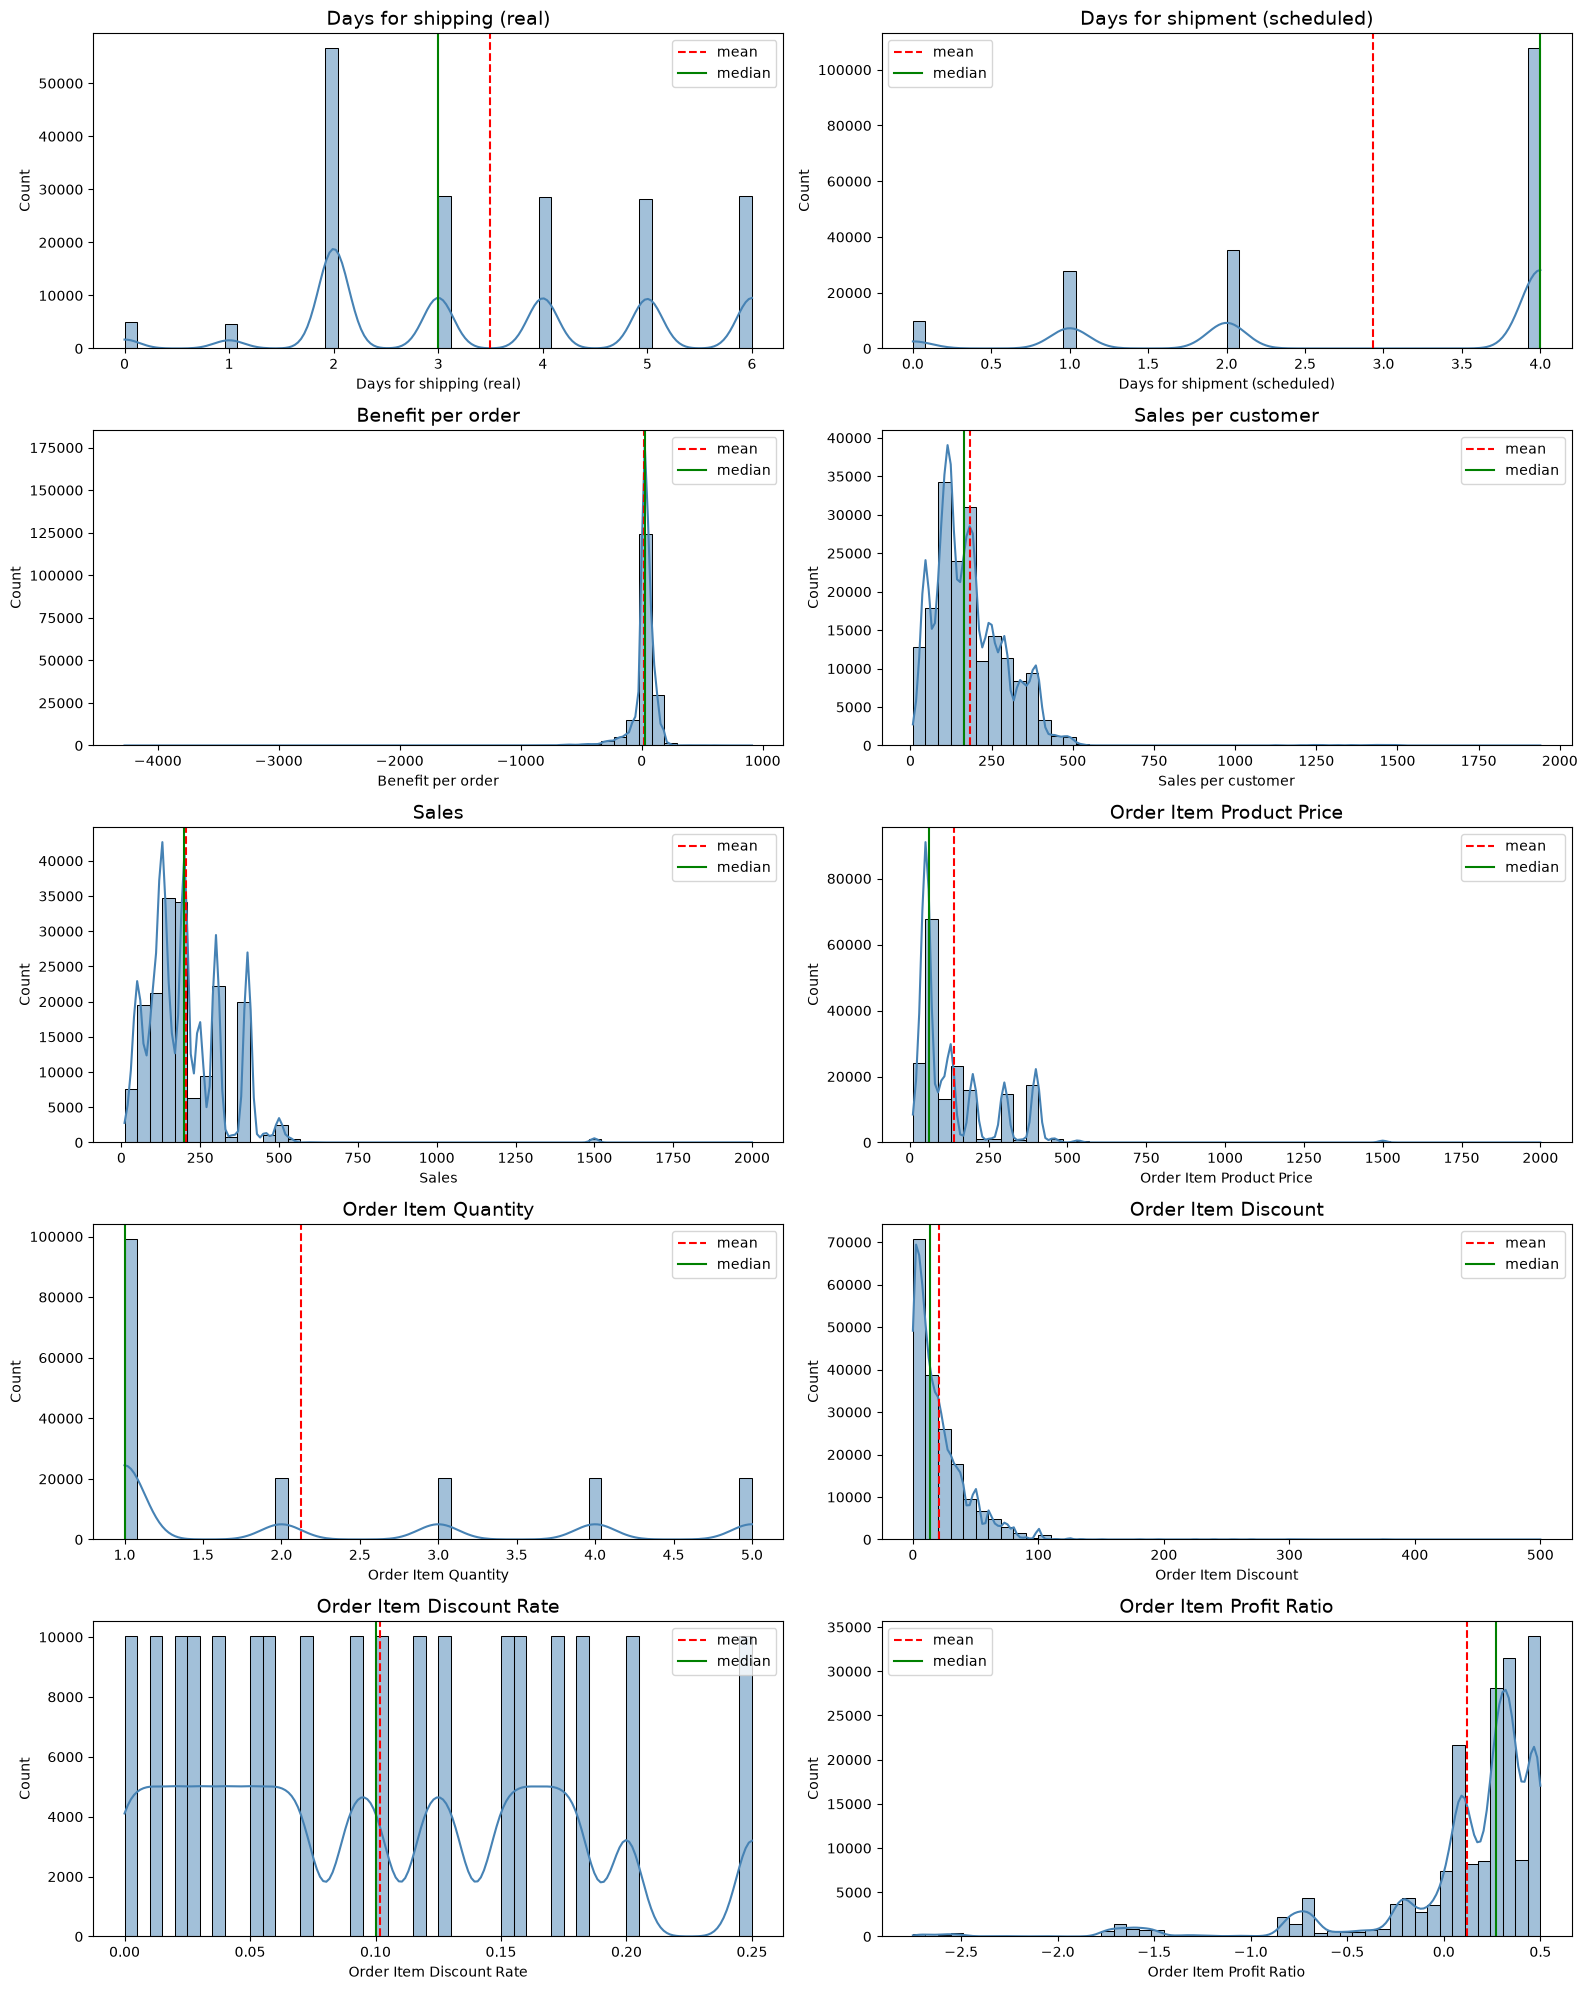

In [48]:
fig, axes = plt.subplots(5, 2, figsize=(16, 20))

for ax, col in zip(axes.flat, numerical_columns):
    sns.histplot(data=df, x=col, bins=50, kde=True, color="steelblue", ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(df[col].median(), color="green", linestyle="-", label="median")
    ax.set_title(col, fontsize=14)
    ax.legend()

plt.tight_layout()
plt.show()

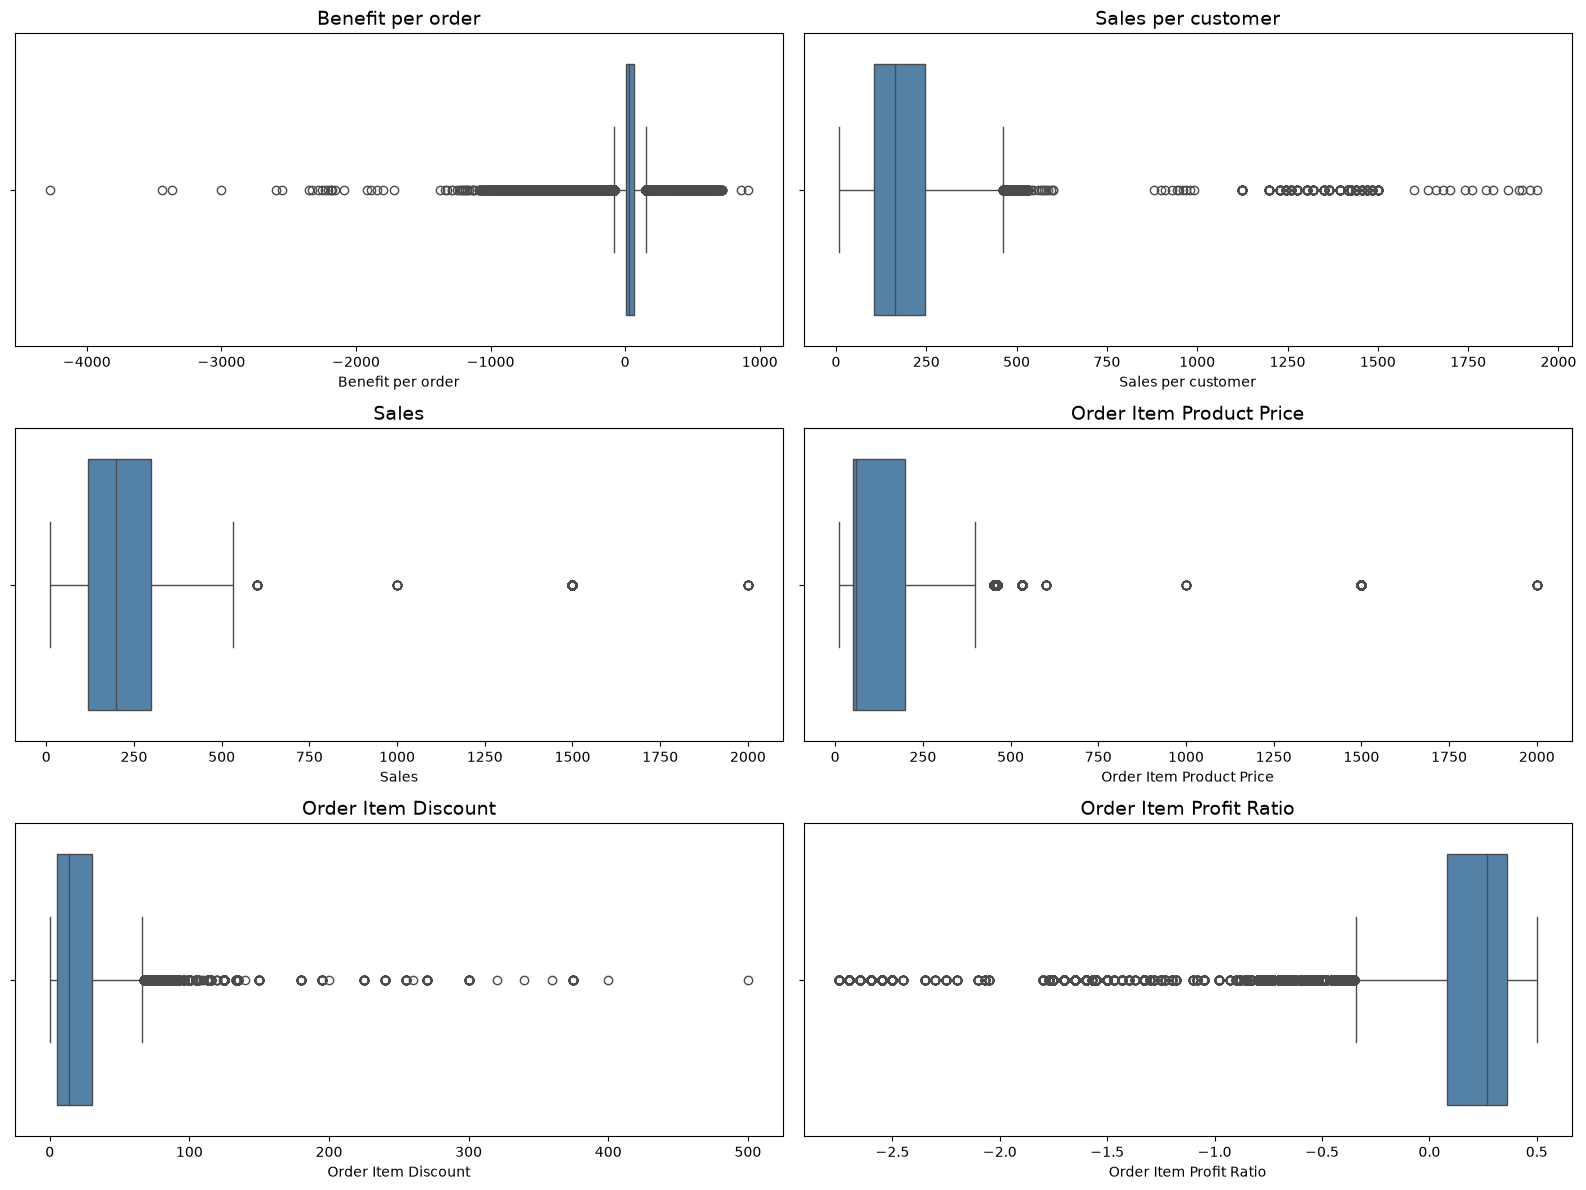

In [49]:
boxplot_columns = [
    "Benefit per order",
    "Sales per customer",
    "Sales",
    "Order Item Product Price",
    "Order Item Discount",
    "Order Item Profit Ratio",
]

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

for ax, col in zip(axes.flat, boxplot_columns):
    sns.boxplot(data=df, x=col, color="steelblue", ax=ax)
    ax.set_title(col, fontsize=14)

plt.tight_layout()
plt.show()

### Univariate numeric findings

**Shape of the data**
- Sales, Sales per customer, Product Price and Order Item Discount are right-skewed. Most values are small and a few are very large.
- Benefit per order has a long tail on the left. The lowest value is about -4,275, so a few orders lost a lot of money.
- Order Item Profit Ratio is left-skewed. Most items have a positive ratio, but there is a small group of loss-making items below 0.

**Discrete columns**
- Days for shipping (real), Days for shipment (scheduled), Order Item Quantity and Order Item Discount Rate only take a few fixed values. They are shown with histograms only, because boxplots do not tell us much for them.
- More than half of the orders are scheduled for 4 days.

**Outliers**
- The boxplots show many outliers in the money columns.
- The high Sales and Price values pile up at a few repeated amounts. These look like real expensive products, not data errors.
- No outliers are removed or capped. These look like real values, and tree models do not need capping.

**Univariate — Categorical**

In [50]:
categorical_cols = ["Type", "Delivery Status", "Category Name", "Customer Segment",
                     "Department Name", "Market", "Order Region", "Order Country",
                     "Order State", "Order City", "Order Status", "Shipping Mode"]

low_card = [c for c in categorical_cols if df[c].nunique() < 30]
high_card = [c for c in categorical_cols if df[c].nunique() >= 30]
print("Low cardinality:", low_card)
print("High cardinality:", high_card)

Low cardinality: ['Type', 'Delivery Status', 'Customer Segment', 'Department Name', 'Market', 'Order Region', 'Order Status', 'Shipping Mode']
High cardinality: ['Category Name', 'Order Country', 'Order State', 'Order City']


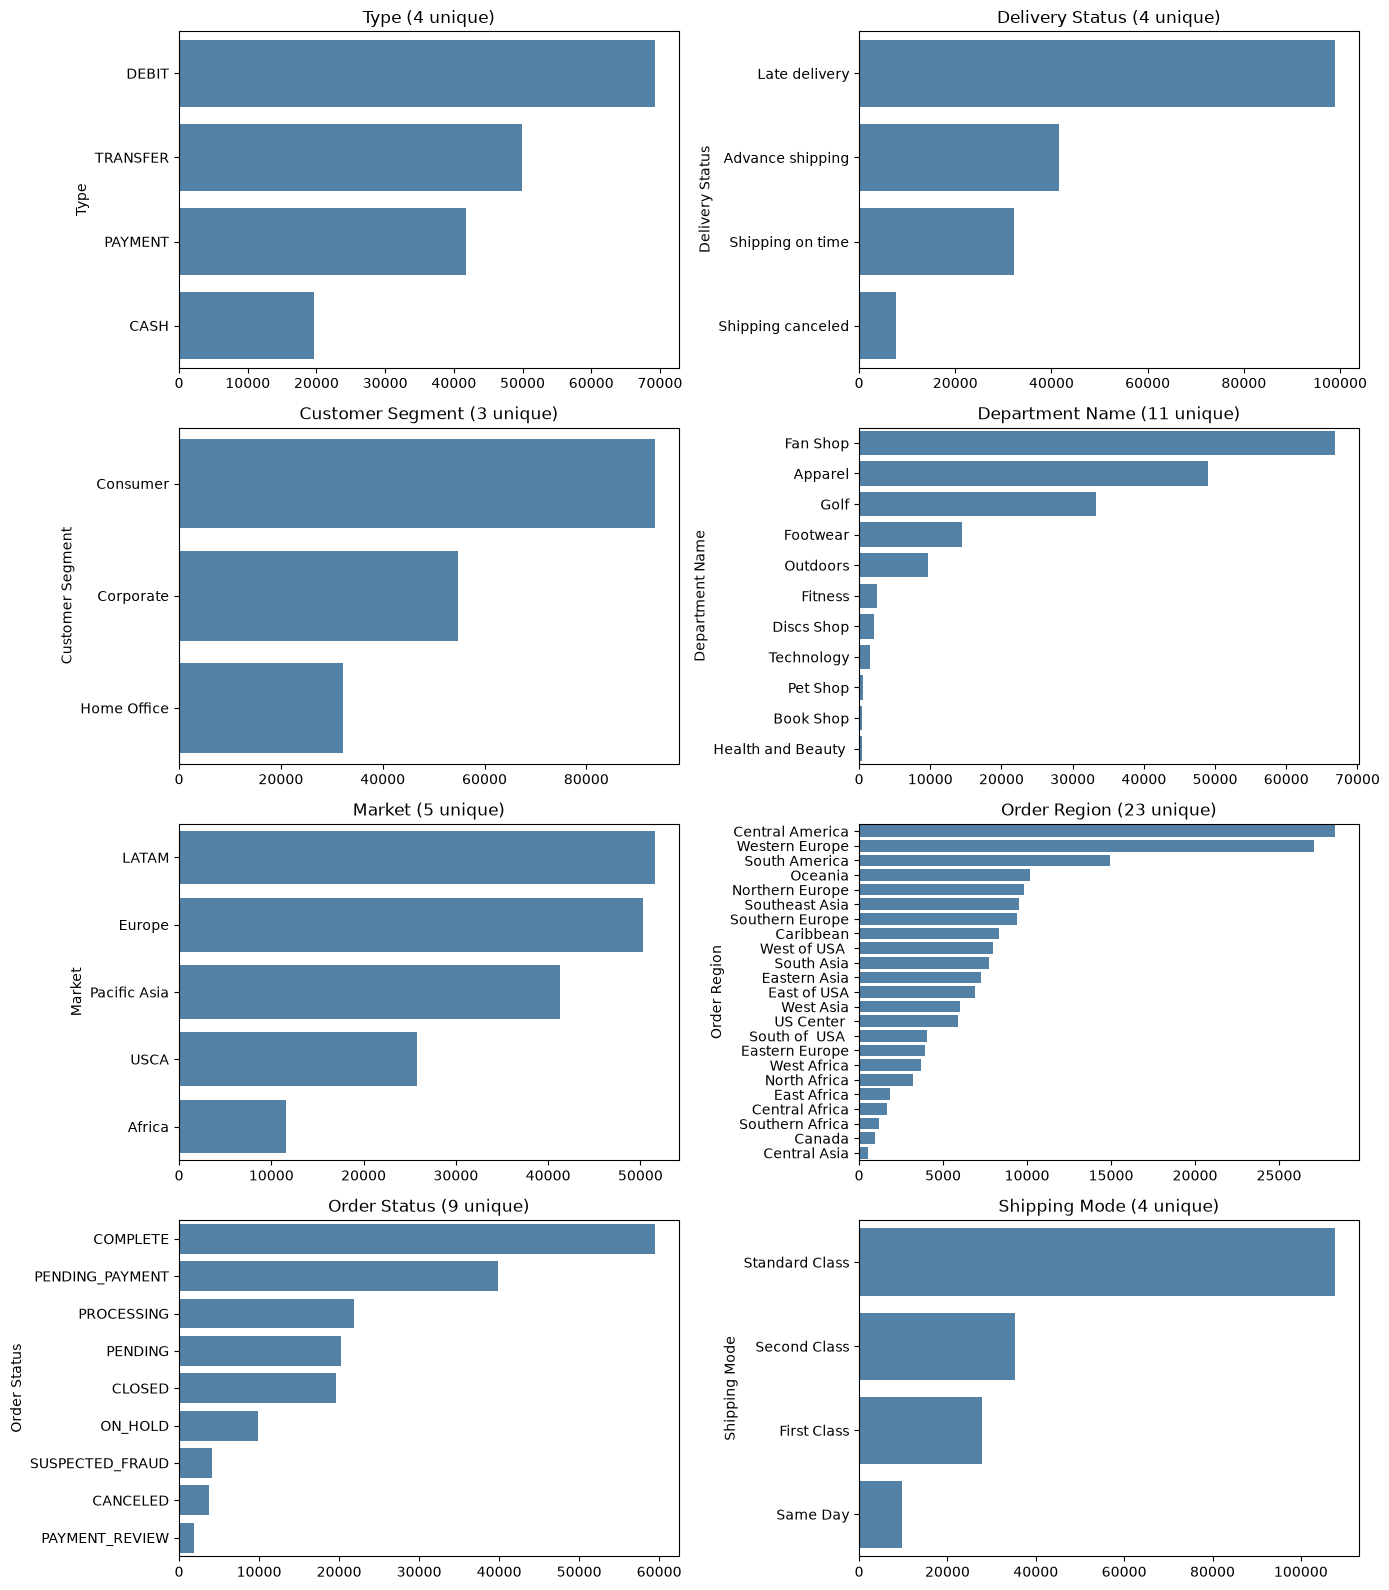

In [51]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for ax, col in zip(axes.flat, low_card):
    counts = df[col].value_counts()
    sns.barplot(x=counts.values, y=counts.index, color="steelblue", ax=ax)
    ax.set_title(f"{col} ({df[col].nunique()} unique)")
plt.tight_layout()
plt.show()

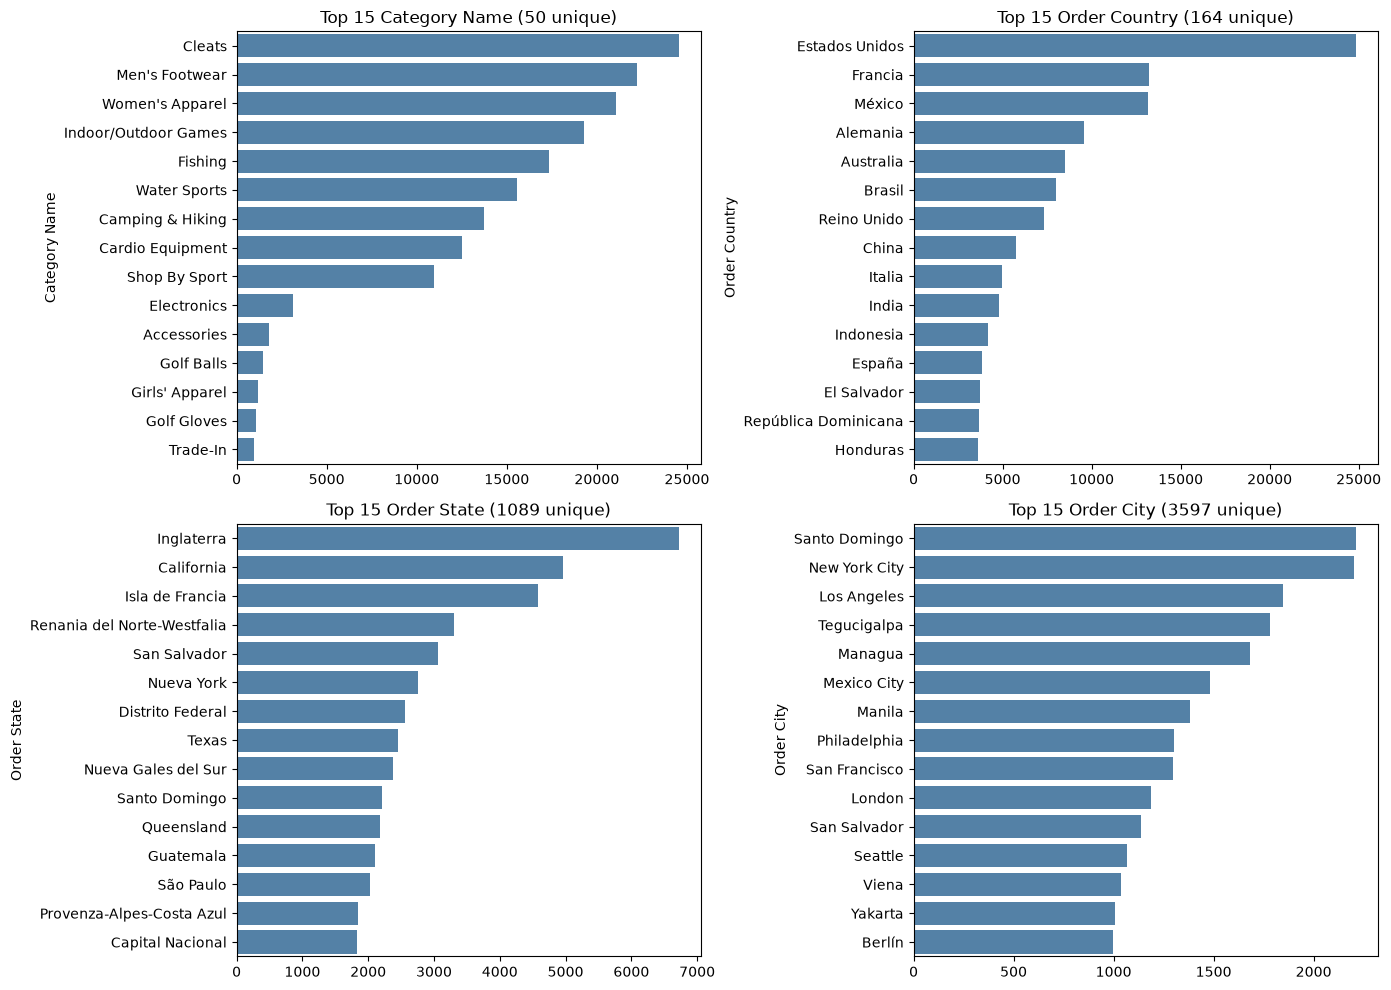

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, high_card):
    counts = df[col].value_counts().head(15)
    sns.barplot(x=counts.values, y=counts.index, color="steelblue", ax=ax)
    ax.set_title(f"Top 15 {col} ({df[col].nunique()} unique)")
plt.tight_layout()
plt.show()

## Target Variable

In [53]:
pd.crosstab(df["Delivery Status"], df["Late_delivery_risk"])


Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


In [54]:
print(df["Late_delivery_risk"].value_counts())
print(df["Late_delivery_risk"].value_counts(normalize=True).mul(100).round(1))

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64
Late_delivery_risk
1    54.8
0    45.2
Name: proportion, dtype: float64


In [55]:
rule = (df["Days for shipping (real)"] > df["Days for shipment (scheduled)"]).astype(int)
match_rate = (rule == df["Late_delivery_risk"]).mean() * 100
print(f"Match rate: {match_rate:.2f}%")

mismatch = df[rule != df["Late_delivery_risk"]]
print("\nMismatched rows by Order Status:")
print(mismatch["Order Status"].value_counts())

Match rate: 97.55%

Mismatched rows by Order Status:
Order Status
SUSPECTED_FRAUD    2316
CANCELED           2107
Name: count, dtype: int64


In [56]:
mismatch = df[rule != df["Late_delivery_risk"]]
print("Mismatched rows:", len(mismatch))

compare = pd.DataFrame({
    "mismatch_%": mismatch["Order Status"].value_counts(normalize=True) * 100,
    "all_rows_%": df["Order Status"].value_counts(normalize=True) * 100,
}).round(1)

compare

Mismatched rows: 4423


,mismatch_%,all_rows_%
Order Status,,
CANCELED,47.6,2.0
CLOSED,NaN,10.9
COMPLETE,NaN,33.0
ON_HOLD,NaN,5.4
PAYMENT_REVIEW,NaN,1.0
PENDING,NaN,11.2
PENDING_PAYMENT,NaN,22.1
PROCESSING,NaN,12.1
SUSPECTED_FRAUD,52.4,2.3


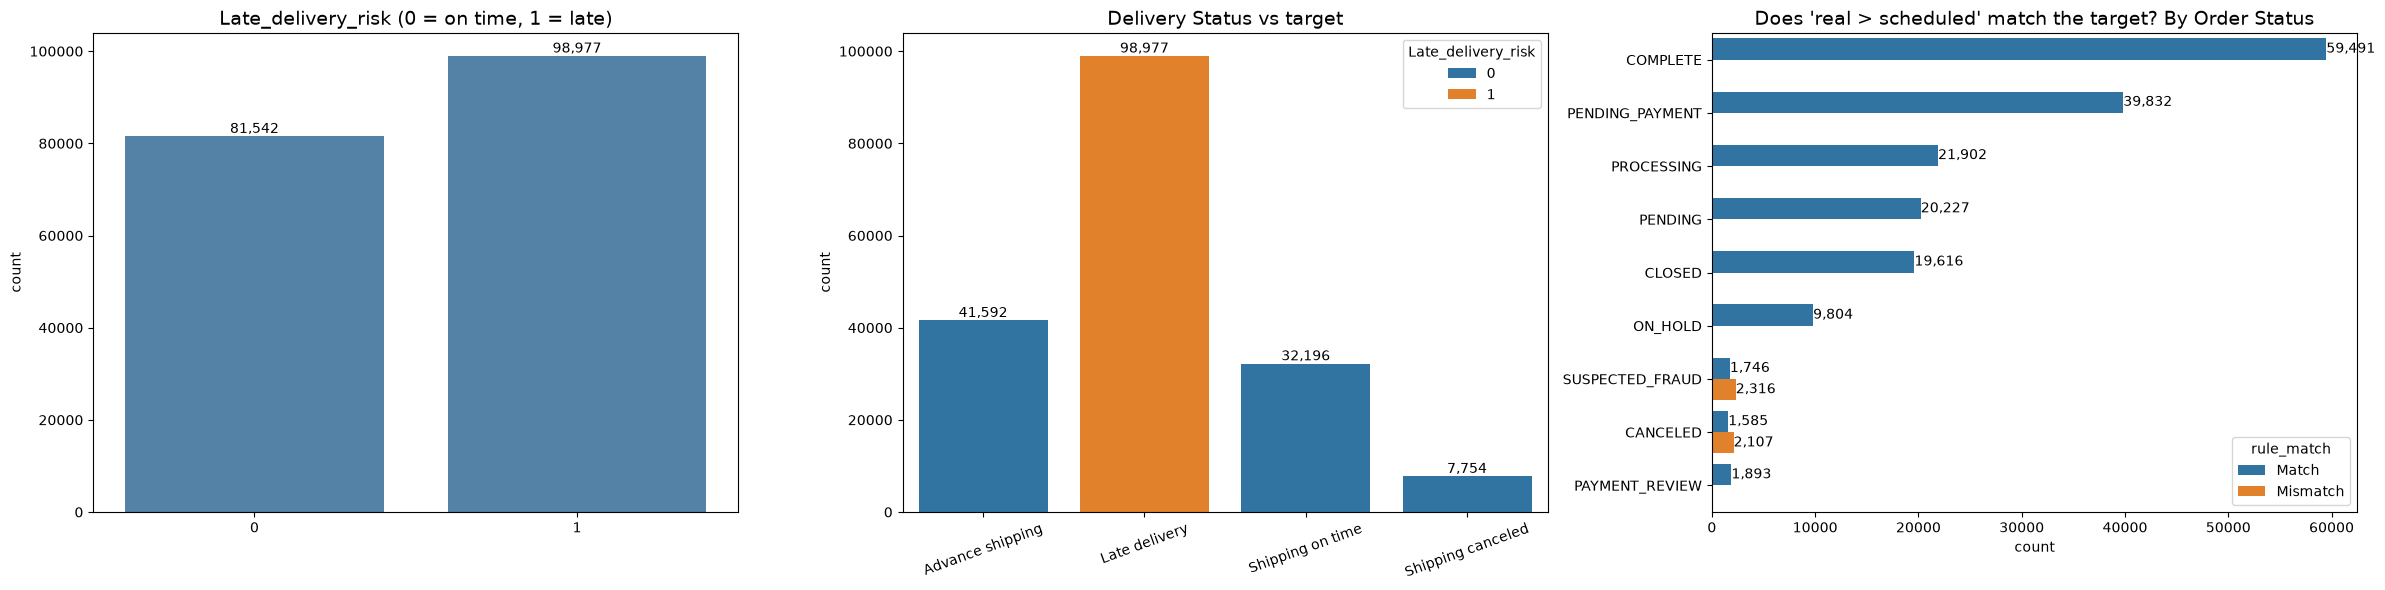

In [57]:
rule = (df["Days for shipping (real)"] > df["Days for shipment (scheduled)"]).astype(int)
df["rule_match"] = np.where(rule == df["Late_delivery_risk"], "Match", "Mismatch")

fig, axes = plt.subplots(1, 3, figsize=(24, 6))

# 1. Target balance
sns.countplot(data=df, x="Late_delivery_risk", color="steelblue", ax=axes[0])
axes[0].set_title("Late_delivery_risk (0 = on time, 1 = late)", fontsize=14)
axes[0].set_xlabel("")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="{:,.0f}")

# 2. Delivery Status vs target
sns.countplot(data=df, x="Delivery Status", hue="Late_delivery_risk", ax=axes[1])
axes[1].set_title("Delivery Status vs target", fontsize=14)
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="{:,.0f}")

# 3. Rule match by Order Status
order = df["Order Status"].value_counts().index
sns.countplot(data=df, y="Order Status", hue="rule_match", order=order, ax=axes[2])
axes[2].set_title("Does 'real > scheduled' match the target? By Order Status", fontsize=14)
axes[2].set_ylabel("")
for c in axes[2].containers:
    axes[2].bar_label(c, fmt="{:,.0f}")

plt.tight_layout()
plt.show()

- The target is fairly balanced: 98,977 late (54.8%) and 81,542 on time (45.2%).
- Delivery Status lines up 1-to-1 with the target. "Late delivery" is always 1, and the other three statuses are always 0. It is the target in words, so it can't be used as a feature.
- The rule "real days > scheduled days" matches the target on 97.55% of rows.
- All 4,423 mismatches come from two Order Status values: SUSPECTED_FRAUD (2,316) and CANCELED (2,107). Every other status matches 100%.
- For those two statuses, mismatches are actually more common than matches. These orders look late by the days columns but are labeled on time.
- 'Shipping canceled' (7,754 rows) is the same group as the CANCELED (3,692) and SUSPECTED_FRAUD (4,062) orders. These orders never shipped.

## Orders that never shipped

Do canceled and suspected fraud orders belong in a late-delivery model?



In [58]:
never_shipped = df["Order Status"].isin(["CANCELED", "SUSPECTED_FRAUD"])
print("Never-shipped rows:", never_shipped.sum())
print(df.loc[never_shipped, "Order Status"].value_counts())
print(pd.crosstab(df["Delivery Status"], never_shipped))
df["order_date"] = pd.to_datetime(df["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
df_ship = df[~never_shipped].copy()
rule_ship = (df_ship["Days for shipping (real)"] > df_ship["Days for shipment (scheduled)"]).astype(int)
print("Rows kept:", len(df_ship))
print("Orders kept:", df_ship["Order Id"].nunique())
print("Late rate:", round(df_ship["Late_delivery_risk"].mean() * 100, 1), "%")
print("Rule match:", (rule_ship == df_ship["Late_delivery_risk"]).mean())

Never-shipped rows: 7754
Order Status
SUSPECTED_FRAUD    4062
CANCELED           3692
Name: count, dtype: int64
Order Status       False  True 
Delivery Status                
Advance shipping   41592      0
Late delivery      98977      0
Shipping canceled      0   7754
Shipping on time   32196      0
Rows kept: 172765
Orders kept: 62897
Late rate: 57.3 %
Rule match: 1.0


## Temporal Distribution

In [59]:
df["order_date"] = pd.to_datetime(df["order date (DateOrders)"])
monthly = df.groupby(df["order_date"].dt.to_period("M")).size()
print("Date range:", df["order_date"].min(), "to", df["order_date"].max())

Date range: 2015-01-01 00:00:00 to 2018-01-31 23:38:00


In [60]:
q = df_ship["order_date"].dt.to_period("Q")
by_q = pd.DataFrame({
    "rows": df_ship.groupby(q).size(),
    "orders": df_ship.groupby(q)["Order Id"].nunique(),
    "late_%": (df_ship.groupby(q)["Late_delivery_risk"].mean() * 100).round(1),
})
by_q["items_per_order"] = (by_q["rows"] / by_q["orders"]).round(2)
orders = df_ship.drop_duplicates("Order Id")[["Customer Id", "order_date"]].copy()
orders["is_new_customer"] = orders["order_date"] == orders.groupby("Customer Id")["order_date"].transform("min")
by_q["new_customer_%"] = (orders.groupby(orders["order_date"].dt.to_period("Q"))["is_new_customer"].mean() * 100).round(1)
by_q

,rows,orders,late_%,items_per_order,new_customer_%
order_date,,,,,
2015Q1,14728,4920,57.1,2.99,82.6
2015Q2,14910,4974,56.9,3.00,55.3
2015Q3,15075,5016,58.3,3.01,37.3
2015Q4,15241,5085,57.0,3.00,25.3
2016Q1,14809,4977,57.5,2.98,16.2
2016Q2,14768,4922,58.5,3.00,11.5
2016Q3,15134,5024,56.4,3.01,7.2
2016Q4,15215,5032,57.6,3.02,5.0
2017Q1,14853,4933,56.8,3.01,3.2


# BIVARIATE ANALYSIS

categorical vs target

Does the late rate change by shipping mode, market, segment, department, type or category? The red line is the overall late rate. Only orders that shipped are used.

In [61]:
overall = df_ship["Late_delivery_risk"].mean() * 100

def late_rate_chart(col):
    g = df_ship.groupby(col)["Late_delivery_risk"].agg(["mean", "size"])
    g["mean"] = g["mean"] * 100
    g = g.sort_values("mean", ascending=False)
    labels = [f"{name} (n={n:,})" for name, n in zip(g.index, g["size"])]

    fig, ax = plt.subplots(figsize=(10, 0.6 * len(g) + 2))
    ax.barh(labels, g["mean"], color="steelblue")
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.axvline(overall, color="red", linestyle="--", label=f"Overall {overall:.1f}%")
    ax.set_xlim(0, 100)   # same scale for every chart, so flat vs strong is obvious
    ax.invert_yaxis()
    ax.set_title(f"Late rate by {col}", fontsize=14)
    ax.set_xlabel("Late rate %")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

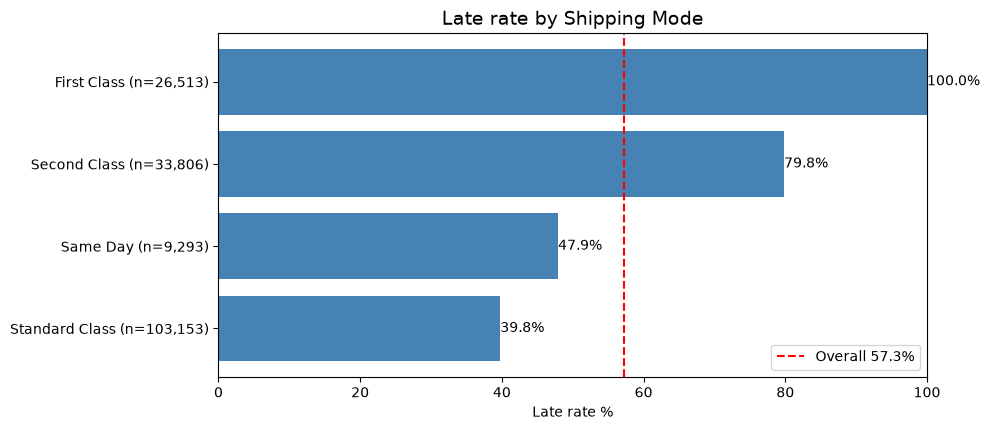

In [62]:
late_rate_chart("Shipping Mode")

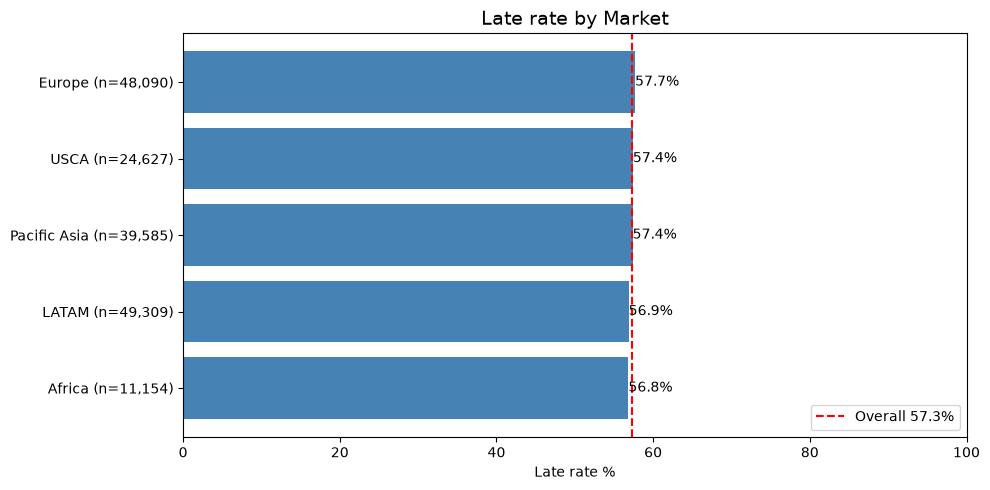

In [63]:
late_rate_chart("Market")

In [64]:
def spread(col, min_rows=1000):
    g = df_ship.groupby(col)["Late_delivery_risk"].agg(["mean", "size"])
    g = g[g["size"] >= min_rows]["mean"] * 100
    return pd.Series({"groups_used": len(g), "lowest_%": g.min(),
                      "highest_%": g.max(), "spread_pts": g.max() - g.min()})

pd.DataFrame({c: spread(c) for c in ["Market", "Order Region", "Order Country", "Order State"]}).T.round(1)

,groups_used,lowest_%,highest_%,spread_pts
Market,5.0,56.8,57.7,0.8
Order Region,21.0,54.7,60.1,5.5
Order Country,31.0,52.3,60.5,8.2
Order State,27.0,51.3,60.4,9.1


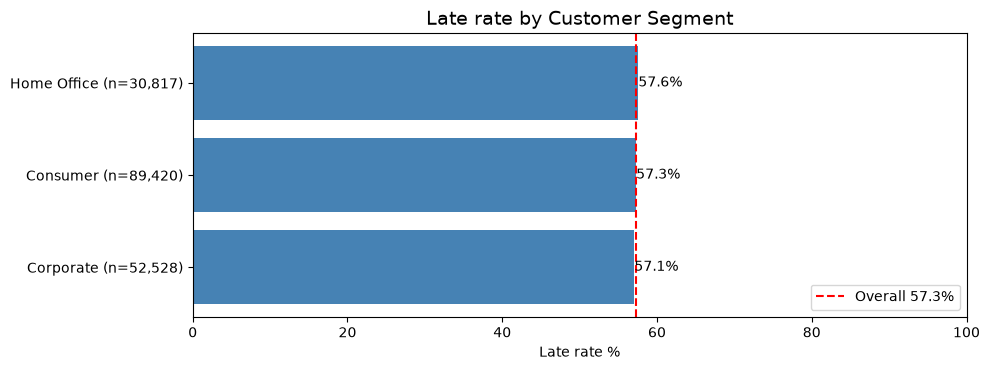

In [65]:
late_rate_chart("Customer Segment")

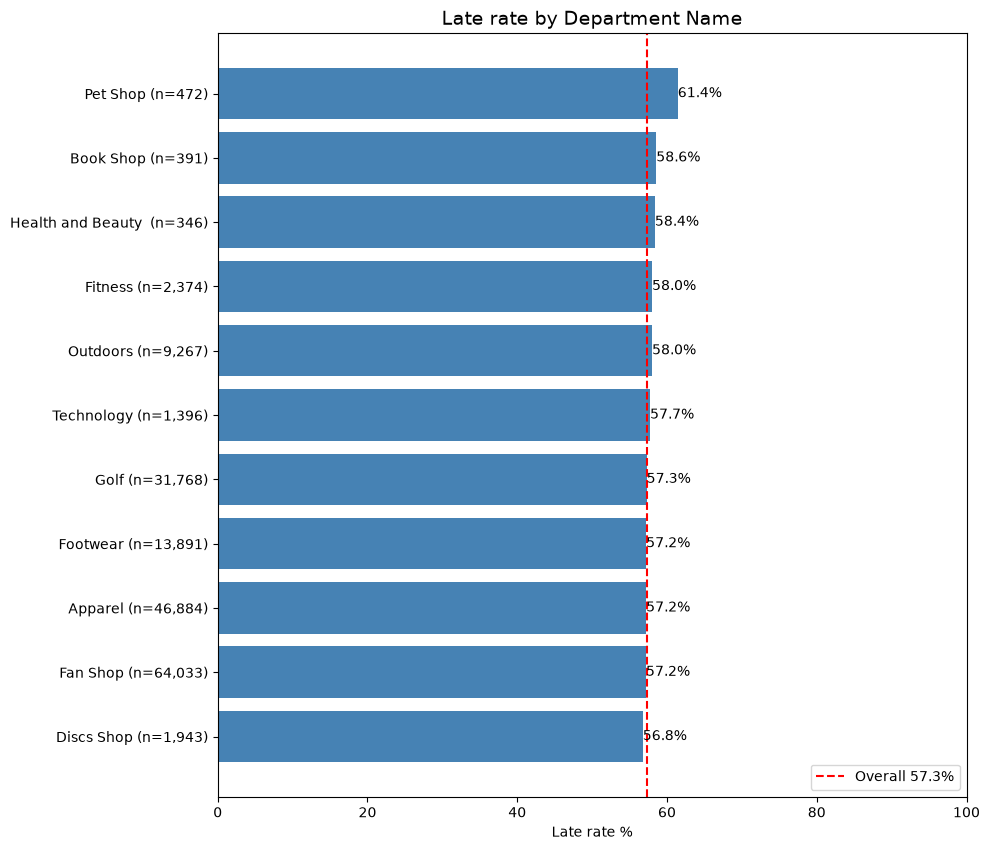

In [66]:
late_rate_chart("Department Name")

In [67]:
pd.DataFrame({c: spread(c) for c in ["Type", "Category Name"]}).T.round(1)

,groups_used,lowest_%,highest_%,spread_pts
Type,4.0,56.6,57.5,0.9
Category Name,14.0,56.9,59.8,2.8


## Correlation



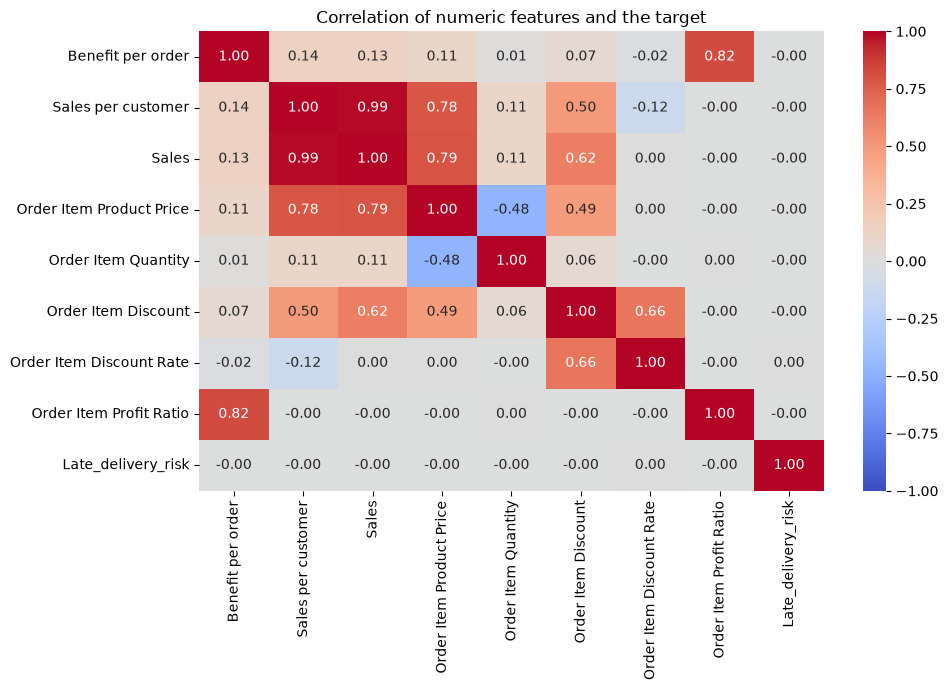

In [68]:
bi_cols = [
    "Benefit per order", "Sales per customer", "Sales", "Order Item Product Price",
    "Order Item Quantity", "Order Item Discount", "Order Item Discount Rate",
    "Order Item Profit Ratio",
]

plt.figure(figsize=(10, 7))
sns.heatmap(df_ship[bi_cols + ["Late_delivery_risk"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of numeric features and the target")
plt.tight_layout()
plt.show()

In [69]:
days = ["Days for shipping (real)", "Days for shipment (scheduled)"]
df_ship[days].corrwith(df_ship["Late_delivery_risk"]).round(2)

Days for shipping (real)         0.42
Days for shipment (scheduled)   -0.39
dtype: float64

### Correlation findings

- Sales and Sales per customer are almost the same column (0.99), so one is enough. Benefit per order and Profit Ratio also move together (0.82).
- All the money, discount and quantity columns have 0.00 correlation with late delivery. They don't help predict it.
- Only the shipping-day columns show any link (real +0.42, scheduled -0.39). Real days are only known after delivery and define the target, so they are not used as features. Scheduled days just repeat what shipping mode already says.